In [1]:
import os, glob
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt

In [2]:
pth_data = os.path.join('..', 'data')
pth_in = os.path.join(pth_data, 'modeling', 'inputs')
pth_mod = os.path.join(pth_data, 'features', 'biomart', 'modules')
# pth_fig = os.path.join('..', 'figures', 'modeling', ''spectrum')
# pth_out = ...

In [3]:
adata = sc.read_h5ad(os.path.join(pth_in, 'development.h5ad'))
adata.obs['t'] = adata.obs.t.astype(float); adata

AnnData object with n_obs × n_vars = 14458 × 14985
    obs: 'sample', 'celltype', 't', 'source'
    obsm: 'X_pca', 'X_umap', 'X_umap_traj'

In [4]:
mod_fn = sorted(glob.glob(os.path.join(pth_mod, '*.csv')))
get_name = lambda fn: os.path.split(fn)[1].replace('.csv', '')
mod_dict = {get_name(fn) : pd.read_csv(fn) for fn in mod_fn}

# module signatures
g_ref = mod_dict['ref'].mmusculus
for mod, df_mod in mod_dict.items():
    if mod != 'ref':
        print(mod)
        g = df_mod.mmusculus.copy()
        g = g.loc[g.isin(adata.var_names)]
        for _, df_group in adata.obs.groupby('source', observed = True):
            msk = adata.obs_names.isin(df_group.index)
            adata_group = adata[msk].copy()
            sc.tl.score_genes(adata_group,
                              gene_list = g,
                              score_name = mod,
                              ctrl_as_ref = False,
                              gene_pool = g_ref,
                              random_state = 1234)
            adata.obs.loc[msk, mod] = adata_group.obs[mod]

early
late


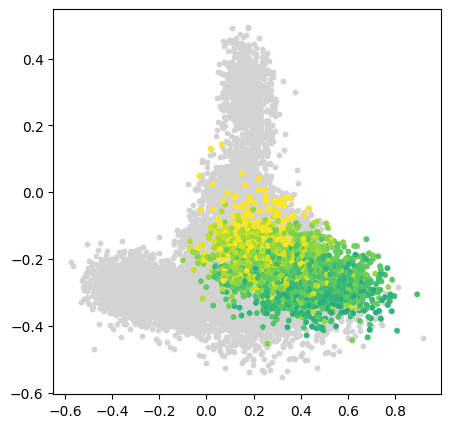

In [20]:
msk_ps = (adata.obs.source == 'GSE162534') & (adata.obs.t > 10)

s = 10
plt.figure(figsize = (5, 5))
plt.scatter(adata.obs.early,
            adata.obs.late,
            c = 'lightgray',
            s = s)
plt.scatter(adata[msk_ps].obs.early,
            adata[msk_ps].obs.late,
            c = adata[msk_ps].obs.t,
            vmin = 0, s = s)
plt.show()

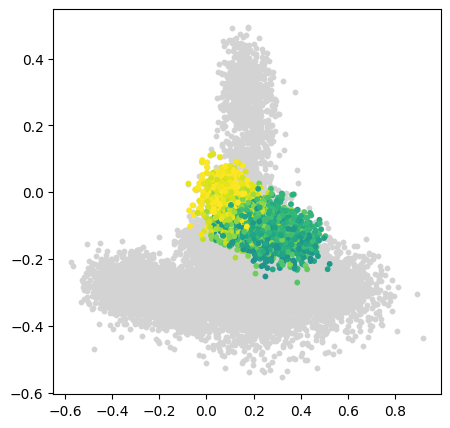

In [21]:
msk_nmp = (adata.obs.source == 'GSE229103') & (adata.obs.t > 6)

s = 10
plt.figure(figsize = (5, 5))
plt.scatter(adata.obs.early,
            adata.obs.late,
            c = 'lightgray',
            s = s)
plt.scatter(adata[msk_nmp].obs.early,
            adata[msk_nmp].obs.late,
            c = adata[msk_nmp].obs.t,
            vmin = 0, s = s)
plt.show()

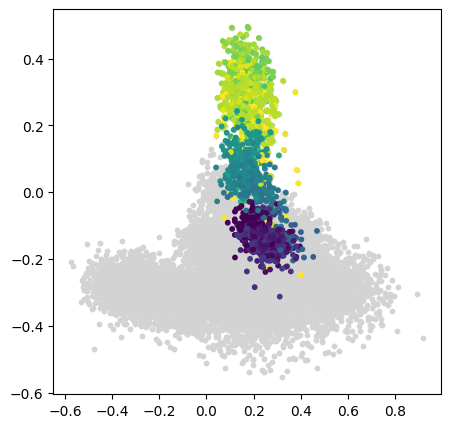

In [22]:
msk_cncc = (adata.obs.source == 'rRNAModifications')

s = 10
plt.figure(figsize = (5, 5))
plt.scatter(adata.obs.early,
            adata.obs.late,
            c = 'lightgray',
            s = s)
plt.scatter(adata[msk_cncc].obs.early,
            adata[msk_cncc].obs.late,
            c = adata[msk_cncc].obs.t,
            vmin = 0, s = s)
plt.show()

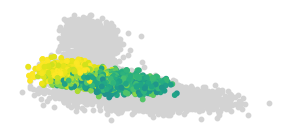

In [31]:
msk = msk_ps | msk_nmp | msk_cncc

s = 10
plt.figure(figsize = (3.5, 1.5))
plt.scatter(adata[msk].obs.early,
            adata[msk].obs.late,
            c = 'lightgray',
            s = s)
plt.scatter(adata[msk_nmp].obs.early,
            adata[msk_nmp].obs.late,
            c = adata[msk_nmp].obs.t,
            vmin = 0, s = s)
plt.axis(False)
plt.show()